In [1]:
# import all the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#load the dataset
df=pd.read_csv('../data/course_lead_scoring_2026.csv')
df.head()


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

# missing values (same as Q1 of this homework)
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

y_train = df_train.converted.values
y_val = df_val.converted.values

# remove the target from the feature dataframes
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [6]:
from sklearn.metrics import roc_auc_score

for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])   # flip the direction
    print(c, round(auc, 3))

number_of_courses_viewed 0.72
annual_income 0.602
interaction_count 0.767
lead_score 0.788


In [7]:
features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]   # probability of class 1, not predict()
print(round(roc_auc_score(y_val, y_pred), 3))

0.729


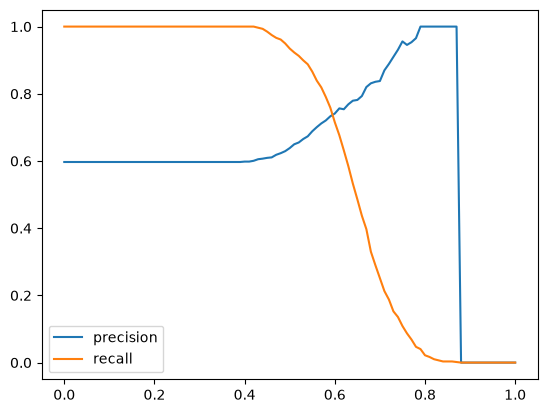

threshold    0.590000
precision    0.733010
recall       0.758794
diff         0.025784
Name: 59, dtype: float64


In [8]:
rows = []
for t in np.arange(0.0, 1.01, 0.01):
    pred = (y_pred >= t)
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((round(t, 2), p, r))

scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])

# plot
import matplotlib.pyplot as plt
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.legend(); plt.show()

# intersection: smallest |P - R|, ignoring rows where both are 0
valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
print(valid.loc[valid['diff'].idxmin()])

In [9]:
scores['f1'] = 2 * scores.precision * scores.recall / (scores.precision + scores.recall)
print(scores.loc[scores.f1.idxmax()])

threshold    0.550000
precision    0.688415
recall       0.865997
f1           0.767062
Name: 55, dtype: float64


In [10]:
from sklearn.model_selection import KFold

df_full_train = df_full_train.reset_index(drop=True)
y_full = df_full_train.converted.values

def cv_scores(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]

        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(d_tr[features].to_dict(orient='records'))
        X_va = dv.transform(d_va[features].to_dict(orient='records'))

        m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        m.fit(X_tr, y_full[train_idx])
        aucs.append(roc_auc_score(y_full[val_idx], m.predict_proba(X_va)[:, 1]))
    return aucs

print(round(np.std(cv_scores(1.0)), 3))

0.012


In [11]:
for C in [0.000001, 0.001, 1]:
    aucs = cv_scores(C)
    print(C, round(np.mean(aucs), 3), round(np.std(aucs), 3))

1e-06 0.616 0.01
0.001 0.744 0.013
1 0.731 0.012
